# 04.2 Random forest (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con el experimento 1 y con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma que en el experimento 1.
- Hiperparámetros: salen de la búsqueda con Optuna del experimento 2 (carpeta `04-hyperparameter-optimization-experiment-2`), con `load_best(...)`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- No usar `test`.

## Hipótesis del experimento 2

El experimento 1 dejó al random forest en macro-F1 0.576 (clasificación) y R² 0.413 (regresión). En este experimento comprobamos si tres cambios lo mejoran. Cada uno es una hipótesis que el resultado confirmará o no.

| Cambio | Hipótesis |
|---|---|
| 1. Raza, color y ciudad con *target encoding* en lugar de one-hot | Con one-hot y el corte del 1 % solo quedan 14 de 329 razas, 16 de 58 colores y 6 de 26 ciudades; el resto se junta en "infrequent". Con *target encoding* cada categoría se cambia por el promedio del objetivo en esa categoría, así que no se pierde ninguna |
| 2. Ampliar `max_depth` (5–60) y `max_features` (0,05–0,8) | Con rangos más amplios, Optuna puede encontrar un bosque mejor |
| 3. Probar `criterion` (`gini` o `entropy`) y `balanced_subsample` en clasificación | Son dos formas de dar más importancia a las clases pequeñas, como `Other`, y podrían subir el macro-F1 |

**Lo que no cambia.** Las 22 variables son las mismas que en el experimento 1. Las transformaciones que ayudaron a SVM y KNN en su experimento 2 (escalar o pasar la edad a logaritmo) no cambian nada en un árbol: cortar por la edad o por su logaritmo separa a los mismos animales. También son iguales la validación, la semilla y el número de pruebas.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from config import SEED
from features import FEATURES, build_preprocessor
from tuning import load_best

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

c:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Variables del experimento 2: las mismas 22 del experimento 1. Lo que cambia es cómo entran raza, color y ciudad (`CAT_HIGH`): con `build_preprocessor(..., cat_high_encoding="target")` se usa *target encoding* en lugar de one-hot. En clasificación, cada variable se convierte en 5 columnas (la proporción de cada salida en esa categoría); en regresión, en una sola (los días promedio, en log).

In [2]:
FEATURES_EXP2_CLF = FEATURES
FEATURES_EXP2_REG = FEATURES

print("El experimento 2 usa estas variables (las mismas que el experimento 1):")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables (las mismas que el experimento 1):
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 2. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [3]:
folder = "../04-hyperparameter-optimization-experiment-2"
params_clf = load_best("rf_clf", FEATURES_EXP2_CLF, folder=folder)
params_reg = load_best("rf_reg", FEATURES_EXP2_REG, folder=folder)

Ajustes cargados de rf_clf.json: {'max_depth': 44, 'min_samples_leaf': 1, 'max_features': 0.610759176702504, 'criterion': 'entropy', 'class_weight': 'balanced_subsample'}
(en la búsqueda: macro-F1 = 0.5319)
Ajustes cargados de rf_reg.json: {'max_depth': 15, 'min_samples_leaf': 3, 'max_features': 0.44356732372417834}
(en la búsqueda: R² (en log) = 0.4123)


## 1. Clasificación

Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio.

macro-F1: 0.566  (siempre la clase más frecuente: 0.119)



                 precision    recall  f1-score   support

       Adoption       0.64      0.79      0.71     27073
     Euthanasia       0.76      0.67      0.71      4986
          Other       0.65      0.10      0.18       834
Return to Owner       0.63      0.63      0.63     11757
       Transfer       0.70      0.52      0.60     19031

       accuracy                           0.66     63681
      macro avg       0.68      0.54      0.57     63681
   weighted avg       0.67      0.66      0.65     63681



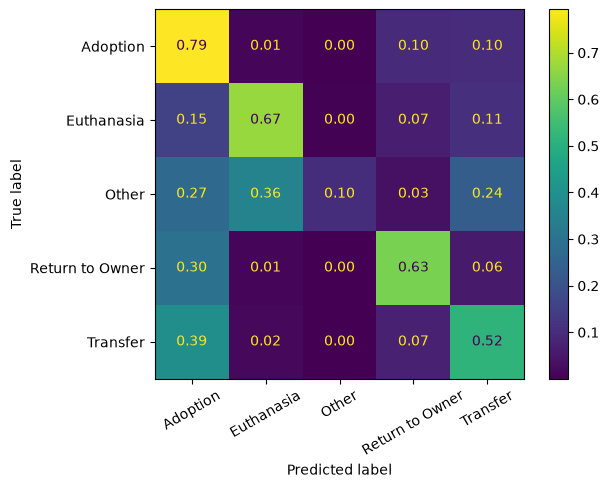

In [4]:
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF, cat_high_encoding="target")),
                     ("model", RandomForestClassifier(random_state=SEED, n_estimators=200, n_jobs=3, **params_clf))])
X_clf = data[FEATURES_EXP2_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

El error se reporta en días (`np.expm1`) y el R² en log.

In [5]:
pipe_reg = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_REG, cat_high_encoding="target")),
                     ("model", RandomForestRegressor(random_state=SEED, n_estimators=200, n_jobs=3, **params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP2_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
base_log = cross_val_predict(DummyRegressor(strategy="median"), X_reg, y_reg, groups=groups_reg, cv=cv)

days_real = np.expm1(y_reg)
pd.DataFrame({
    "R² (log)": [r2_score(y_reg, pred_log), r2_score(y_reg, base_log)],
    "MAE (días)": [mean_absolute_error(days_real, np.expm1(pred_log)), mean_absolute_error(days_real, np.expm1(base_log))],
}, index=["Random forest", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
Random forest,0.431,18.615
Siempre la mediana,-0.058,24.312


## 3. Resultados frente al experimento 1

In [6]:
exp1 = {"Clasificación (macro-F1)": 0.576, "Regresión (R² log)": 0.413, "Regresión (MAE días)": 18.556}  # Random forest, experimento 1
exp2 = {"Clasificación (macro-F1)": f1_score(y_clf, pred_clf, average="macro"),
        "Regresión (R² log)": r2_score(y_reg, pred_log),
        "Regresión (MAE días)": mean_absolute_error(days_real, np.expm1(pred_log))}

pd.DataFrame({"Experimento 1": exp1, "Experimento 2": exp2}).T.round(3)

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
Experimento 1,0.576,0.413,18.556
Experimento 2,0.566,0.431,18.615


## 4. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Los folds son los mismos que en el experimento 1, así que se pueden comparar uno a uno: si el experimento 2 gana en todos los folds, la diferencia no es casualidad. No vuelve a entrenar nada: usa las predicciones de arriba.

In [7]:
EXP1_FOLDS_CLF = [0.573, 0.579, 0.583, 0.568, 0.574]  # macro-F1 por fold, experimento 1
EXP1_FOLDS_REG = [0.406, 0.39, 0.437, 0.401, 0.427]  # R² (log) por fold, experimento 1

rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

rows_reg = []
for fold, (_, val) in enumerate(cv.split(X_reg, y_reg, groups_reg), start=1):
    rows_reg.append({"fold": fold, "filas": len(val),
                     "R² (log)": r2_score(y_reg.iloc[val], pred_log[val]),
                     "MAE (días)": mean_absolute_error(days_real.iloc[val], np.expm1(pred_log[val]))})

for title, rows, metric, exp1_folds in [("Clasificación", rows_clf, "macro-F1", EXP1_FOLDS_CLF),
                                        ("Regresión", rows_reg, "R² (log)", EXP1_FOLDS_REG)]:
    table = pd.DataFrame(rows).set_index("fold")
    table[f"{metric} exp. 1"] = exp1_folds
    table["diferencia"] = table[metric] - table[f"{metric} exp. 1"]
    summary = table.drop(columns="filas").agg(["mean", "std"])
    print(f"=== {title}: resultado por fold ===")
    print(table.round(3).to_string())
    print(summary.round(3).to_string())
    print(f"El experimento 2 gana en {(table['diferencia'] > 0).sum()} de 5 folds.\n")

=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud  macro-F1 exp. 1  diferencia
fold                                                         
1     12729     0.558      0.659            0.573      -0.015
2     12783     0.571      0.661            0.579      -0.008
3     12697     0.567      0.658            0.583      -0.016
4     12733     0.563      0.668            0.568      -0.005
5     12739     0.567      0.666            0.574      -0.007
      macro-F1  exactitud  macro-F1 exp. 1  diferencia
mean     0.565      0.662            0.575      -0.010
std      0.005      0.004            0.006       0.005
El experimento 2 gana en 0 de 5 folds.

=== Regresión: resultado por fold ===
      filas  R² (log)  MAE (días)  R² (log) exp. 1  diferencia
fold                                                          
1      5393     0.423      18.948            0.406       0.017
2      5453     0.411      18.737            0.390       0.021
3      5401     0.454      18